In [ ]:
# Henry Westfall
# 3/26/2026

In [ ]:
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt

# Forward/Inverse Position Kinematics for a 2-member 2-DOF arm

In [ ]:
# simple forward kinematics for a 2 DOF arm

def solve_limb(lengths, angles):
    pts = np.zeros((len(lengths), 2))
    pos = np.zeros(2)
    ang = 0.0

    for i in range(len(lengths)):
        ang += angles[i]
        pos = pos + np.array([
            lengths[i] * np.cos(ang),
            lengths[i] * np.sin(ang)
        ])
        pts[i] = pos

    return pts

def solve_toe(lengths, angles):
    return solve_limb(lengths, angles)[-1]

In [ ]:
# inverse kinematics for a 2 DOF arm
def jacobian(a, b, h, k):
  return np.array([
      [-a*np.sin(h) - b*np.sin(h+k), -b*np.sin(h+k)],
      [ a*np.cos(h) + b*np.cos(h+k),  b*np.cos(h+k)]
  ])

def position_solve_jacobian(a, b, task_local, q0, step=0.5, timeout=1000, thresh=1e-4):
    q = np.array(q0, dtype=float)
    lengths = np.array([a, b], dtype=float)

    for _ in range(timeout):
      toe = solve_toe(lengths, q)
      err = task_local - toe

      if np.linalg.norm(err) < thresh:
          break

      J = jacobian(a, b, q[0], q[1])
      dq = np.linalg.pinv(J) @ err
      q = q + step * dq

    return q

def velocity_solve_jacobian(a, b, xdot_des, q, qdot0):
  q = np.array(q, dtype=float)
  qdot = np.array(qdot0, dtype=float)

  J = jacobian(a, b, q[0], q[1])
  J_inv = np.linalg.pinv(J) @ xdot_des
  qdot = J_inv @ xdot_des

  return qdot

def acceleration_solve_jacobian(a, b, xdotdot_des, q, qdotdot0):
  q = np.array(q, dtype=float)
  qdotdot = np.array(qdotdot0, dtype=float)

  J = jacobian(a, b, q[0], q[1])
  J_inv = np.linalg.pinv(J) @ xdotdot_des
  qdotdot = J_inv @ xdotdot_des

  return qdotdot

def solve_arm_position_world(a, b, base, task_world, q0):
  task_local = np.array(task_world) - np.array(base)
  return position_solve_jacobian(a, b, task_local, q0)

def solve_arm_velocity_world(a, b, base, xdot_des_world, q0, qdot0):
  xdot_des_local = np.array(xdot_des_world) - np.array(base)
  return velocity_solve_jacobian(a, b, xdot_des_local, qdot0)

# Source - https://stackoverflow.com/a/55817881
# Posted by mujjiga, modified by community. See post 'Timeline' for change history
# Retrieved 2026-03-26, License - CC BY-SA 4.0
def circle_circle_intersections(c1, c2, r):
    # circle 1: (x0, y0), radius r0
    # circle 2: (x1, y1), radius r1

    x0, y0 = c1
    x1, y1 = c2
    d=np.sqrt((x1-x0)**2 + (y1-y0)**2)

    # non intersecting
    if d > 2 * r:
        return None
    # One circle within other
    if d < 0:
        return None
    # coincident circles
    if d == 0:
        return None
    else:
        a=(d**2)/(2*d)
        h=np.sqrt(r**2-a**2)
        x2=x0+a*(x1-x0)/d
        y2=y0+a*(y1-y0)/d
        x3=x2+h*(y1-y0)/d
        y3=y2-h*(x1-x0)/d

        x4=x2-h*(y1-y0)/d
        y4=y2+h*(x1-x0)/d

        P1 = np.array((x3, y3))
        P2 = np.array((x4, y4))

        return P1, P2


In [ ]:
# methods for solution visualization
def plot_limb(lengths, angles, base=(0,0), plot_style='b-'):
    prev = np.array(base, dtype=float)
    ang = 0.0

    for i, L in enumerate(lengths):
        ang += angles[i]
        joint = prev + np.array([L*np.cos(ang), L*np.sin(ang)])
        plt.plot([prev[0], joint[0]], [prev[1], joint[1]], plot_style)
        prev = joint

def plot_task(task):
  x, y = task
  plt.plot(x, y, "ro")

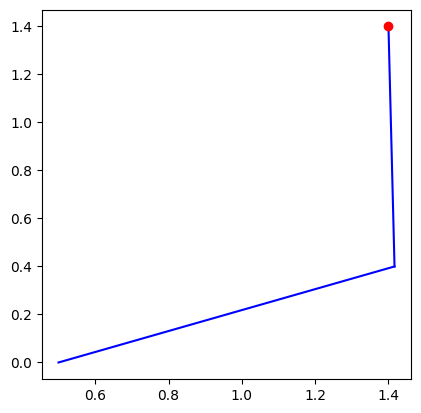

[0.41160683 1.17569919]


In [ ]:
# test
offset = np.array((0.5, 0))
lengths = np.array((1.0, 1.0))
task = np.array((1.4, 1.4))

q = solve_arm_position_world(lengths[0], lengths[1], offset, task, q0=[0.3, 0.3])
# solution_angles = inverse_kinematics(task, lengths)

fig, ax = plt.subplots()
ax.set_box_aspect(1)

plot_limb(lengths, q, offset)
plot_task(task)
plt.show()

print(q)

# Inverse Position Kinematics for 5-Bar Linkage
Model: solve vector lengths for two linear actuators that constrain each other. Then, solve 2-member IK for those linear actuators.

In [ ]:
def get_S(P, C):
  # this is just simple vector math!
  # P is input, C is a system parameter
  return P, P - C

In [ ]:
def get_toggled_arm_solution_branch(q, L, desired_sign):
  # Take cross product of (elbow - base) and (end - elbow)
  # Assume local, so base is origin.
  limb = solve_limb(L, q)
  E = limb[0]
  P = limb[1]
  EP = P - E

  z = np.cross(EP, E)
  z_sign = np.sign(z)

  if z_sign != desired_sign:
    # change to the other config using geometry
    q2 = -q[1]

    A = L[0] + L[1] * np.cos(q2)
    B = L[1] * np.sin(q2)

    x, y = P
    q1 = np.atan2(y, x) - np.atan2(B, A)

    return np.array([q1, q2])
  else:
    return q

In [ ]:
# example
c_length = 0.1 # m
b_length = 0.1 # m
f_length = 0.2 # m
L = np.array([b_length, f_length])

# arm bases
B1 = np.array([0.0, 0.0])
B2 = np.array([c_length, 0.0])

# task position
P = np.array((0.1, 0.2))

# Solve 2-member IK as tasks
q1 = solve_arm_position_world(b_length, f_length, B1, P, q0=[0.3, 0.3])
q2 = solve_arm_position_world(b_length, f_length, B2, P, q0=[2.8, -0.3])

# Ensure arms are on the correct branches using cross products.
# One arm should be "up" and one should be "down"
q1 = get_toggled_arm_solution_branch(q1, L, 1)
q2 = get_toggled_arm_solution_branch(q2, L, -1)

# to demonstrate the alternative, show the incorrect version
q1_prime = get_toggled_arm_solution_branch(q1, L, -1)
q2_prime = get_toggled_arm_solution_branch(q2, L, 1)

print(f'Left angles:\tθ={round(q1[0], 4)}\tφ={round(q1[1], 4)}')
print(f'Right angles:\tθ={round(q2[0], 4)}\tφ={round(q2[1], 4)}')

Left angles:	θ=2.2147	φ=-39.2701
Right angles:	θ=6.5354	φ=-4.4592


/tmp/ipykernel_543/1679720820.py:9: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  z = np.cross(EP, E)


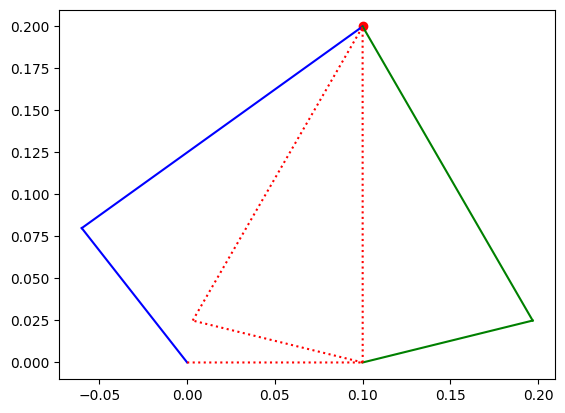

In [ ]:
# Visualize the example
plot_task(P)
L = np.array([b_length, f_length])
plot_limb(L, q1, B1, 'b-')
plot_limb(L, q2, B2, 'g-')
plot_limb(L, q1_prime, B1, 'r:')
plot_limb(L, q2_prime, B2, 'r:')

# Forward/Inverse Kinematics for 5-bar linkage (Actuated Velocity & Acceleration Model)
This is a closed-loop solution for finding actuator output velocity/acceleration as a function of input ONLY.

This is a simplified version of an approach I developed at Sung Lab last summer to cleanly mechanical integrate constraints into inverse kinematics on systems with partial actuation.

In [ ]:
# define constraints and generalized constraint Jacobian (Jc) rows
def link_constraint(joint_A, joint_B, length, positions):
  r0 = positions[joint_A]
  r1 = positions[joint_B]
  return length - np.linalg.norm(r0 - r1)

def fixed_x(joint, fix_x, positions):
  r0 = positions[joint]
  return fix_x - r0[0]

def fixed_y(joint, fix_y, positions):
  r0 = positions[joint]
  return fix_y - r0[1]

def del_link_constraint(joint_A, joint_B, length, positions, partials):
  r0 = positions[joint_A]
  r1 = positions[joint_B]
  del_r0 = partials[joint_A]
  del_r1 = partials[joint_B]

  diff = r1 - r0
  norm_diff = np.linalg.norm(diff)

  return (diff / norm_diff) @ (del_r1 - del_r0)

def del_fixed_x(joint, positions, partials):
  del_r0 = partials[joint]
  return -del_r0[0]

def del_fixed_y(joint, positions, partials):
  del_r0 = partials[joint]
  return -del_r0[1]

def get_r(joint, positional_q):
    idx = joint
    return np.array(positional_q[2*idx:2*(idx+1)])

def get_del_r(idx, positional_q):
  row = np.zeros((2, positional_q.shape[0]))
  row[:, 2*idx:2*(idx+1)] = np.eye(2)
  return row

def get_positions_and_partials(positional_q, n=5):
  positions = np.array([get_r(joint, positional_q) for joint in range(n)])
  partials = np.array([get_del_r(joint, positional_q) for joint in range(n)])
  return positions, partials

In [ ]:
# Model the linkage as a pentagon. Each vertex has an index.
# The origin vertex is 0, and indices increment clockwise

def get_positional_q(q1_full, q2_full, B1, B2, L):
  # turn q1_full and q2_full into the position q
  limb1_local = solve_limb(L, q1_full)
  limb2_local = solve_limb(L, q2_full)

  elbow_1, end_1 = limb1_local + B1
  elbow_2, _ = limb2_local + B2

  # flatten these limbs
  q = np.concatenate((B1, elbow_1, end_1, elbow_2, B2))
  return q.flatten()

def build_position_residuals(positions, L, n=5):
  # link constraints (constrains 5 DOF)
  residuals = []
  for i, length in enumerate(L):
    residuals.append(link_constraint(i%n, (i+1)%n, length, positions))

  # motor locations are fixed, so constrain their x and y (constrains 3 DOF)
  residuals.append(fixed_x(0, positions[0][0], positions))
  residuals.append(fixed_y(0, positions[0][1], positions))
  residuals.append(fixed_y(4, positions[4][1], positions))
  residuals.append(fixed_y(4, positions[4][0], positions)) #<-- redundant with length constraint!

  return np.array(residuals)

def build_geometric_jacobian(positions, partials, L, n=5):
  # This maps del residuals / del q. Each col is a different q_i
  # add link constraints (constrains 5 DOF)
  jacobian = []
  for i, length in enumerate(L):
    jacobian.append(del_link_constraint(i % n, (i + 1) % n, length, positions, partials))

  # motor locations are fixed, so constrain their x and y (constrains 3 DOF)
  jacobian.append(del_fixed_x(0, positions, partials))
  jacobian.append(del_fixed_y(0, positions, partials))
  jacobian.append(del_fixed_y(4, positions, partials))
  jacobian.append(del_fixed_x(4, positions, partials)) #<-- redundant with length constraint!

  return np.vstack(jacobian)

def solve_5_bar_velocities(theta_1_dot, theta_2_dot, positional_q, Ls_path):
  # Given motor speeds, find joint velocities
  positions, pos_partials = get_positions_and_partials(positional_q)
  J_complete = build_geometric_jacobian(positions, pos_partials, Ls_path)

  # coordinate indices, not joint indices
  elbow_coord_idxs = np.array([2, 3, 6, 7])   # joints 1 and 3 in 2D
  rest_coord_idxs  = np.array([0, 1, 4, 5, 8, 9])

  J_geom_rest  = J_complete[:, rest_coord_idxs]
  J_geom_elbow = J_complete[:, elbow_coord_idxs]

  theta_1 = np.atan2(positions[1][1] - positions[0][1],
                      positions[1][0] - positions[0][0])
  theta_2 = np.atan2(positions[3][1] - positions[4][1],
                      positions[3][0] - positions[4][0])

  b = Ls_path[-1]   # assuming proximal length

  # elbow coordinate velocities from motor speeds
  q_dot_elbow = np.array([
      -b * np.sin(theta_1) * theta_1_dot,
        b * np.cos(theta_1) * theta_1_dot,
      -b * np.sin(theta_2) * theta_2_dot,
        b * np.cos(theta_2) * theta_2_dot
  ])

  q_dot_rest = -np.linalg.pinv(J_geom_rest) @ (J_geom_elbow @ q_dot_elbow)
  q_dot_end_effector = q_dot_rest[2:4] # middle 2 points of 6
  q_dot = np.concatenate((q_dot_rest[0:2], q_dot_elbow[0:2], q_dot_end_effector, q_dot_elbow[2:4], q_dot_rest[4:6]))
  return q_dot_end_effector, q_dot, J_geom_rest, J_geom_elbow

def solve_5_bar_angular_speeds(task_xdot, task_ydot, positional_q, Ls_path):
  # Given velocities at P, find motor speeds
  positions, pos_partials = get_positions_and_partials(positional_q)
  J_complete = build_geometric_jacobian(positions, pos_partials, Ls_path)

  # determine current angles
  theta_1 = np.atan2(positions[1][1] - positions[0][1],
                      positions[1][0] - positions[0][0])
  theta_2 = np.atan2(positions[3][1] - positions[4][1],
                      positions[3][0] - positions[4][0])

  b = Ls_path[-1]

  # coordinate indices, not joint indices
  end_coord_idxs = np.array([4, 5])   # joints 3 in 2D
  rest_coord_idxs  = np.array([0, 1, 2, 3, 6, 7, 8, 9])
  elbow_coord_idxs = np.array([2, 3, 6, 7])   # joints 1 and 3 in 2D

  J_geom_rest  = J_complete[:, rest_coord_idxs]
  J_geom_end = J_complete[:, end_coord_idxs]

  # determine full qdot from task
  q_dot_end = np.array([task_xdot, task_ydot]) # task
  q_dot_rest = -np.linalg.pinv(J_geom_rest) @ (J_geom_end @ q_dot_end)
  q_dot = np.concatenate((q_dot_rest[0:4], q_dot_end, q_dot_rest[4:8]))

  # extract elbow from q_dot
  q_dot_elbow = q_dot[elbow_coord_idxs] # velocities, we want angular
  v1 = q_dot_elbow[0:2]
  v2 = q_dot_elbow[2:4]

  t1 = np.array([-np.sin(theta_1), np.cos(theta_1)])
  t2 = np.array([-np.sin(theta_2), np.cos(theta_2)])

  theta_1_dot = np.dot(v1, t1) / b
  theta_2_dot = np.dot(v2, t2) / b
  q_ang = np.array([theta_1_dot, theta_2_dot]) # this is the solution

  return q_ang, q_dot, J_geom_rest, J_geom_end

## TEST: Motor Driving End Effector (velocity)

In [ ]:
# Motor driving end effector

# ==== INITIAL CONFIGURATION ==== #
c_length = 0.1 # m
b_length = 0.1 # m
f_length = 0.2 # m
L = np.array([b_length, f_length])

# arm bases
B1 = np.array([0.0, 0.0])
B2 = np.array([c_length, 0.0])

# task position
P = np.array((0.1, 0.2))

# Solve 2-member IK as tasks
q1 = solve_arm_position_world(b_length, f_length, B1, P, q0=[0.3, 0.3])
q2 = solve_arm_position_world(b_length, f_length, B2, P, q0=[2.8, -0.3])

# Ensure arms are on the correct branches using cross products.
# One arm should be "up" and one should be "down"
q1 = get_toggled_arm_solution_branch(q1, L, 1)
q2 = get_toggled_arm_solution_branch(q2, L, -1)

# ==== VELOCITY TEST ==== #
Ls_path = [c_length, b_length, f_length, f_length, b_length] # loops around pentagon
Ls_branch = [b_length, f_length] # only one branch

theta_1 = q1[0]
theta_2 = q2[0]
theta_1_dot = 7.5
theta_2_dot = 7.5
dt = 1e-4

# Solve initial joint velocities
positional_q = get_positional_q(q1, q2, B1, B2, Ls_branch)
qdot_end, qdot, _, _ = solve_5_bar_velocities(theta_1_dot, theta_2_dot, positional_q, Ls_path)

# Calculate guess based on velocities
q_pred_next = (positional_q + qdot * dt).round(8)

# Move angles by TRUE speed to get TRUE case
theta_1 = theta_1 + theta_1_dot * dt
theta_2 = theta_2 + theta_2_dot * dt
E1_new = np.array([b_length * np.cos(theta_1), b_length * np.sin(theta_1)]) + B1
E2_new = np.array([b_length * np.cos(theta_2), b_length * np.sin(theta_2)]) + B2
cands = circle_circle_intersections(E1_new, E2_new, f_length)
if cands is None:
    raise ValueError("No valid intersection after timestep")
P_new = min(cands, key=lambda p: np.linalg.norm(p - P))
q_true_next = np.hstack([B1, E1_new, P_new, E2_new, B2])

# Check guess against truth
print("Predicted next q:", q_pred_next)
print("\nTrue next q:     ", q_true_next)
print("\nError norm:      ", np.linalg.norm(q_pred_next - q_true_next))

Predicted next q: [ 0.          0.         -0.06009201  0.07993094  0.09983767  0.20002467
  0.19681662  0.02503092  0.1         0.        ]

True next q:      [ 0.          0.         -0.060092    0.07993092  0.09987966  0.19996871
  0.1968166   0.02503092  0.1         0.        ]

Error norm:       6.996373721902604e-05


/tmp/ipykernel_543/1679720820.py:9: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  z = np.cross(EP, E)


In [ ]:
print(qdot_end)
print(np.linalg.norm(qdot_end))

[-0.82290448  0.32497984]
0.884750630986992


## TEST: Motor speeds for required end effector task (velocity)

In [ ]:
# End effector task --> motor speeds
# This test relies on the FK version above.

# Set truth
theta_1_dot_true = 0.5
theta_2_dot_true = 1.0

# Determine end effector vel at truth
qdot_end_true, qdot_true, _, _ = solve_5_bar_velocities(
    theta_1_dot_true, theta_2_dot_true, positional_q, Ls_path
)

# See if we can IK back to truth from just end effector
q_ang_rec, qdot_rec, J_rest, J_end = solve_5_bar_angular_speeds(
    qdot_end_true[0], qdot_end_true[1], positional_q, Ls_path
)

print("true angular speeds     =", np.array([theta_1_dot_true, theta_2_dot_true]))
print("recovered angular speeds=", q_ang_rec)
print("angular speed error     =", q_ang_rec - np.array([theta_1_dot_true, theta_2_dot_true]))
print("angular speed error norm=", np.linalg.norm(q_ang_rec - np.array([theta_1_dot_true, theta_2_dot_true])))

true angular speeds     = [0.5 1. ]
recovered angular speeds= [0.5 1. ]
angular speed error     = [ 1.11022302e-16 -1.11022302e-15]
angular speed error norm= 1.1157603309187458e-15


## Application

In [ ]:
# End effector task: 6.708 m/s (direction negligible)

# ==== INITIAL CONFIGURATION ==== #
c_length = 0.3 # m
b_length = 0.30 # m
f_length = 0.20 # m
L = np.array([b_length, f_length])

# arm bases
B1 = np.array([0.0, 0.0])
B2 = np.array([c_length, 0.0])

# task position
P = np.array((0.1, 0.2))

# Solve 2-member IK as tasks
q1 = solve_arm_position_world(b_length, f_length, B1, P, q0=[0.3, 0.3])
q2 = solve_arm_position_world(b_length, f_length, B2, P, q0=[2.8, -0.3])

# Ensure arms are on the correct branches using cross products.
# One arm should be "up" and one should be "down"
q1 = get_toggled_arm_solution_branch(q1, L, 1)
q2 = get_toggled_arm_solution_branch(q2, L, -1)

positional_q = get_positional_q(q1, q2, B1, B2, Ls_branch)

# ==== VELOCITY TEST ==== #
Ls_path = [c_length, b_length, f_length, f_length, b_length] # loops around pentagon
Ls_branch = [b_length, f_length] # only one branch

task_pdot = np.array((10, 0)) # required striker speed
sample_angles = np.linspace(np.pi / 4, 3 * np.pi / 4, 10)
motor_speeds = np.zeros((len(sample_angles), 2))

for i, angle in enumerate(sample_angles):
  task_xdot = task_pdot[0] * np.cos(angle)
  task_ydot = task_pdot[0] * np.sin(angle)

  # Solve initial joint velocities
  q_ang_rec, qdot_rec, J_rest, J_end = solve_5_bar_angular_speeds(
    task_xdot, task_ydot, positional_q, Ls_path
  )
  motor_speeds[i] = q_ang_rec

print(motor_speeds)
print("Median speed [rad/s]:", np.median(np.abs(motor_speeds)))
print("Max speed [rad/s]:", np.max(np.abs(motor_speeds)))


[[-14.14068674 -37.2780566 ]
 [ -6.55623658 -35.42132769]
 [  1.22742152 -32.48833967]
 [  8.97378503 -28.56820988]
 [ 16.44748463 -23.7800495 ]
 [ 23.42143573 -18.26934434]
 [ 29.68373836 -12.2035344 ]
 [ 35.04411561  -5.76692625]
 [ 39.33969515   0.84490704]
 [ 42.43995796   7.43106826]]
Median speed [rad/s]: 20.84539003662033
Max speed [rad/s]: 42.439957959242676


/tmp/ipykernel_543/1679720820.py:9: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  z = np.cross(EP, E)


# 5-bar Position-Speed-Force Profile
How do rotational speeds and torques at the inputs relate to linear speeds and forces at the output?

From:
x_dot = J(q) * q_dot, and
x_dotdot = J(q) * q_dotdot

|J(q)| can be thought of as how q_dot or q_dotdot scales into positional movement.

However, since only θ is actuated, we actually don't care about the magnitudes of the φ rows. We thus ignore them.


In [ ]:
# determine workspace bounds
table_width_ft = 3 # ft
table_width = table_width_ft / 3.281 # m
workspace_depth_offset = 0.3 # m
workspace_depth_ft = 1.5 # ft
workspace_depth = workspace_depth_ft / 3.281 + workspace_depth_offset # m

# create sample points within the workspace
N = 5
X = np.linspace(0, table_width, N)
Y = np.linspace(workspace_depth_offset, workspace_depth, N)
xv, yv = np.meshgrid(X, Y)

# set up the arm
c_length = 0.1 # m
b_length = 0.2 # m
f_length = 0.3 # m
L = np.array([b_length, f_length])
center = table_width / 2
B1 = np.array([center - c_length / 2, 0.0])
B2 = np.array([center + c_length / 2, 0.0])

# input motor speeds
theta_1_dot = 1
theta_2_dot = 1

In [ ]:
data_horiz = np.zeros((N, N))
data_vert = np.zeros((N, N))
for i, x in enumerate(X):
  for j, y in enumerate(Y):
    P = np.array((x, y))

    # Solve 2-member IK as tasks
    q1 = solve_arm_position_world(b_length, f_length, B1, P, q0=[0.3, 0.3])
    q2 = solve_arm_position_world(b_length, f_length, B2, P, q0=[2.8, -0.3])

    # Ensure arms are on the correct branches using cross products.
    # One arm should be "up" and one should be "down"
    q1 = get_toggled_arm_solution_branch(q1, L, 1)
    q2 = get_toggled_arm_solution_branch(q2, L, -1)

    # get end effector speed for these motor inputs
    Ls_path = [c_length, b_length, f_length, f_length, b_length] # loops around pentagon
    Ls_branch = [b_length, f_length] # only one branch
    positional_q = get_positional_q(q1, q2, B1, B2, Ls_branch)
    qdot_end = solve_5_bar_velocities(theta_1_dot, theta_2_dot, positional_q, Ls_path)[0]

    # Log
    data_horiz[i, j] = qdot_end[0]
    data_vert[i, j] = qdot_end[1]

/tmp/ipykernel_543/1679720820.py:9: DeprecationWarning: Arrays of 2-dimensional vectors are deprecated. Use arrays of 3-dimensional vectors instead. (deprecated in NumPy 2.0)
  z = np.cross(EP, E)
